# **Assignment 3: Adversarial Attacks**

- Student Name: Cuong Chi Nguyen
- Student ID: 23520199

_Note: The results lie in [section 3](#3.-Experiments-and-Evaluation)_

- [3.1. Attack Success Rate](#3.1.-Attack-Success-Rate)
  - [3.1.1. Direct Attack Success Rate](#3.1.1.-Direct-Attack-Success-Rate)
  - [3.1.2. Transfer Attack Success Rate](#3.1.2.-Transfer-Attack-Success-Rate)
- [3.2. Perturbation Visualization](#3.2.-Perturbation-Visualization)
  - [3.2.1. FGSM from ResNet50](#3.2.1.-FGSM-from-ResNet50)
  - [3.2.2. FGSM from ViT-B/16](#3.2.2.-FGSM-from-ViT-B/16)
  - [3.2.3. PGD from ResNet50](#3.2.3.-PGD-from-ResNet50)
  - [3.2.4. PGD from ViT-B/16](#3.2.4.-PGD-from-ViT-B/16)


# 1. Preparation


## 1.1. Importing Libraries


In [1]:
from huggingface_hub import login

login()

In [2]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision.transforms as T
from torchvision.models import resnet50, ResNet50_Weights, vit_b_16, ViT_B_16_Weights
from datasets import load_dataset
import matplotlib.pyplot as plt
import numpy as np
import random
import urllib.request
import gc
from tqdm import tqdm
from PIL import Image

In [3]:
STUDENT_ID = 23520199
random.seed(STUDENT_ID)
np.random.seed(STUDENT_ID)
torch.manual_seed(STUDENT_ID)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {device}")

Device: cuda


## 1.2. Preparing Dataset and Models


In [4]:
url = "https://raw.githubusercontent.com/pytorch/hub/master/imagenet_classes.txt"
imagenet_classes = [line.strip() for line in urllib.request.urlopen(url)]
imagenet_classes = [
    name.decode("utf-8") if isinstance(name, bytes) else name
    for name in imagenet_classes
]

In [ ]:
dataset = load_dataset("imagenet-1k", split="validation", streaming=True)
dataset_iterator = iter(dataset.shuffle(seed=STUDENT_ID, buffer_size=10000))

images = []
labels = []

with tqdm(total=100, desc="Loading 100 images") as pbar:
    while len(images) < 100:
        sample = next(dataset_iterator)
        img = sample["image"]

        if img.mode == "RGB":  # ensure RGB images
            images.append(img)
            labels.append(sample["label"])
            pbar.update(1)

Resolving data files:   0%|          | 0/294 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/28 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/294 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/28 [00:00<?, ?it/s]

Loading 100 images: 100%|██████████| 100/100 [00:16<00:00,  6.14it/s]


In [6]:
print("Loading CNN Model (ResNet50)...")
cnn_weights = ResNet50_Weights.IMAGENET1K_V1
cnn_model = resnet50(weights=cnn_weights).to(device)
cnn_model.eval()
cnn_preprocess = cnn_weights.transforms()

Loading CNN Model (ResNet50)...


In [7]:
print("Loading ViT Model (ViT-B/16)...")
vit_weights = ViT_B_16_Weights.IMAGENET1K_V1
vit_model = vit_b_16(weights=vit_weights).to(device)
vit_model.eval()
vit_preprocess = vit_weights.transforms()

Loading ViT Model (ViT-B/16)...


In [8]:
# Preprocess images for both models
cnn_inputs = torch.stack([cnn_preprocess(img) for img in images])
vit_inputs = torch.stack([vit_preprocess(img) for img in images])

# Convert labels to tensor
labels = torch.tensor(labels)

# 2. Adversarial Attack Methods


In [9]:
def get_upper_lower_limits(device):
    mean = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1).to(device)
    std = torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1).to(device)
    lower_limit = (0.0 - mean) / std
    upper_limit = (1.0 - mean) / std
    return lower_limit, upper_limit

## 2.1. Fast Gradient Sign Method (FGSM)


In [10]:
def fgsm_attack(model, inputs, labels, epsilon=0.05):
    inputs_gpu = inputs.clone().detach().to(device)
    labels_gpu = labels.to(device)
    inputs_gpu.requires_grad = True

    outputs = model(inputs_gpu)
    loss = F.cross_entropy(outputs, labels_gpu)

    model.zero_grad()
    loss.backward()
    data_grad = inputs_gpu.grad.data

    sign_data_grad = data_grad.sign()
    perturbed_images = inputs_gpu + epsilon * sign_data_grad

    lower_limit, upper_limit = get_upper_lower_limits(device)

    # Clip the perturbed images to ensure they are within the valid range
    perturbed_images = torch.max(torch.min(perturbed_images, upper_limit), lower_limit)

    result = perturbed_images.detach().cpu()

    del inputs_gpu, labels_gpu, outputs, loss, data_grad, perturbed_images
    torch.cuda.empty_cache()

    return result

## 2.2. Projected Gradient Descent (PGD)


In [11]:
def pgd_attack(model, images, labels, epsilon=8 / 255, alpha=2 / 255, iters=10):
    images_gpu = images.clone().detach().to(device)
    labels_gpu = labels.clone().detach().to(device)

    lower_limit, upper_limit = get_upper_lower_limits(device)

    # Initialize the perturbed images with random noise within the epsilon ball
    perturbed_images = images_gpu + torch.empty_like(images_gpu).uniform_(
        -epsilon, epsilon
    )

    # Clip the perturbed images to ensure they are within the valid range
    perturbed_images = torch.max(torch.min(perturbed_images, upper_limit), lower_limit)

    for i in range(iters):
        perturbed_images.requires_grad = True

        outputs = model(perturbed_images)
        loss = F.cross_entropy(outputs, labels_gpu)

        model.zero_grad()
        loss.backward()
        data_grad = perturbed_images.grad.data

        perturbed_images = perturbed_images.detach() + alpha * data_grad.sign()

        # Project the perturbation to the epsilon ball
        delta = torch.clamp(perturbed_images - images_gpu, min=-epsilon, max=epsilon)

        # Clip the perturbed images to ensure they are within the valid range
        perturbed_images = torch.max(
            torch.min(images_gpu + delta, upper_limit), lower_limit
        ).detach()

    result = perturbed_images.cpu()

    del images_gpu, labels_gpu, perturbed_images, outputs, loss, data_grad, delta
    torch.cuda.empty_cache()

    return result

## 2.3. Generating Adversarial Examples


In [12]:
epsilon = 0.05

In [13]:
print("Generating Adversarial Examples from CNN model...")
cnn_fgsm_adv = fgsm_attack(cnn_model, cnn_inputs, labels, epsilon=epsilon)
cnn_pgd_adv = pgd_attack(cnn_model, cnn_inputs, labels, epsilon=epsilon)

Generating Adversarial Examples from CNN model...


In [14]:
print("Generating Adversarial Examples from ViT model...")
vit_fgsm_adv = fgsm_attack(vit_model, vit_inputs, labels, epsilon=epsilon)
vit_pgd_adv = pgd_attack(vit_model, vit_inputs, labels, epsilon=epsilon)

Generating Adversarial Examples from ViT model...


# 3. Experiments and Evaluation


## 3.1. Attack Success Rate


In [15]:
def calculate_asr(model, clean_inputs, adv_inputs, true_labels):
    model.eval()

    clean_inputs_gpu = clean_inputs.to(device)
    adv_inputs_gpu = adv_inputs.to(device)
    true_labels_gpu = true_labels.to(device)

    with torch.no_grad():
        clean_preds = model(clean_inputs_gpu).argmax(dim=1)
        adv_preds = model(adv_inputs_gpu).argmax(dim=1)

    correct_base = clean_preds == true_labels_gpu
    success_attack = (adv_preds != true_labels_gpu) & correct_base

    if correct_base.sum().item() == 0:
        asr = 0.0
    else:
        asr = success_attack.sum().item() / correct_base.sum().item()

    del (
        clean_inputs_gpu,
        adv_inputs_gpu,
        true_labels_gpu,
        clean_preds,
        adv_preds,
        correct_base,
        success_attack,
    )
    torch.cuda.empty_cache()

    return asr * 100

### 3.1.1. Direct Attack Success Rate


In [16]:
cnn_fgsm_asr = calculate_asr(cnn_model, cnn_inputs, cnn_fgsm_adv, labels)
cnn_pgd_asr = calculate_asr(cnn_model, cnn_inputs, cnn_pgd_adv, labels)
vit_fgsm_asr = calculate_asr(vit_model, vit_inputs, vit_fgsm_adv, labels)
vit_pgd_asr = calculate_asr(vit_model, vit_inputs, vit_pgd_adv, labels)

In [17]:
print(f"ASR of FGSM on CNN Model: {cnn_fgsm_asr:.2f}%")
print(f"ASR of PGD on CNN Model:  {cnn_pgd_asr:.2f}%")
print(f"ASR of FGSM on ViT Model: {vit_fgsm_asr:.2f}%")
print(f"ASR of PGD on ViT Model:  {vit_pgd_asr:.2f}%")

ASR of FGSM on CNN Model: 88.31%
ASR of PGD on CNN Model:  100.00%
ASR of FGSM on ViT Model: 61.73%
ASR of PGD on ViT Model:  92.59%


PGD consistently outperforms FGSM in direct attacks across both architectures. However, **the ViT-B/16 model exhibits higher intrinsic robustness**, sustaining lower ASRs against both attack methods compared to the ResNet50.


### 3.1.2. Transfer Attack Success Rate


In [18]:
# Transfer CNN-crafted -> ViT
x_cnn_fgsm_vit_asr = calculate_asr(vit_model, vit_inputs, cnn_fgsm_adv, labels)
x_cnn_pgd_vit_asr = calculate_asr(vit_model, vit_inputs, cnn_pgd_adv, labels)
# Transfer ViT-crafted -> CNN
x_vit_fgsm_cnn_asr = calculate_asr(cnn_model, cnn_inputs, vit_fgsm_adv, labels)
x_vit_pgd_cnn_asr = calculate_asr(cnn_model, cnn_inputs, vit_pgd_adv, labels)

In [19]:
print(f"ASR (FGSM-CNN -> ViT Model): {x_cnn_fgsm_vit_asr:.2f}%")
print(f"ASR (PGD-CNN -> ViT Model):  {x_cnn_pgd_vit_asr:.2f}%")
print(f"ASR (FGSM-ViT -> CNN Model): {x_vit_fgsm_cnn_asr:.2f}%")
print(f"ASR (PGD-ViT -> CNN Model):  {x_vit_pgd_cnn_asr:.2f}%")

ASR (FGSM-CNN -> ViT Model): 8.64%
ASR (PGD-CNN -> ViT Model):  7.41%
ASR (FGSM-ViT -> CNN Model): 14.29%
ASR (PGD-ViT -> CNN Model):  10.39%


Transfer attack success rates are exceptionally low in both directions, indicating that **the two chosen models rely on fundamentally different learned feature representations**. Despite this, ViT-crafted perturbations generalize slightly better to the CNN (ResNet50) than the reverse.


## 3.2. Perturbation Visualization


In [20]:
def plot_visualization(
    source_model,
    target_model,
    clean_images,
    adv_images,
    labels,
    indices,
    classes,
    attack_name="PGD Perturbation",
    source_name="ViT",
    target_name="ResNet",
):
    plt.figure(figsize=(15, 4 * len(indices)))

    source_model.eval()
    target_model.eval()

    # ImageNet normalization stats
    mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
    std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

    for i, idx in enumerate(indices):
        clean_img = clean_images[idx]
        adv_img = adv_images[idx]
        true_label = labels[idx].item()

        # De-normalize
        c_img = clean_img * std + mean
        a_img = adv_img * std + mean

        # Calculate normolized noise
        noise_raw = a_img - c_img
        noise_norm = (noise_raw / (2 * noise_raw.abs().max() + 1e-8)) + 0.5

        # Convert to HWC format for Matplotlib
        c_img_disp = np.clip(c_img.numpy().transpose(1, 2, 0), 0, 1)
        a_img_disp = np.clip(a_img.numpy().transpose(1, 2, 0), 0, 1)
        noise_disp = np.clip(noise_norm.numpy().transpose(1, 2, 0), 0, 1)

        with torch.no_grad():
            clean_gpu = clean_img.unsqueeze(0).to(device)
            adv_gpu = adv_img.unsqueeze(0).to(device)

            src_clean_pred = classes[source_model(clean_gpu).argmax(dim=1).item()]
            tgt_clean_pred = classes[target_model(clean_gpu).argmax(dim=1).item()]

            src_adv_pred = classes[source_model(adv_gpu).argmax(dim=1).item()]
            tgt_adv_pred = classes[target_model(adv_gpu).argmax(dim=1).item()]

        t_label_name = classes[true_label]

        # Plotting Original
        plt.subplot(len(indices), 3, i * 3 + 1)
        plt.imshow(c_img_disp)
        plt.title(
            f"Original\nGT: {t_label_name}\n{source_name}: {src_clean_pred}\n{target_name}: {tgt_clean_pred}"
        )
        plt.axis("off")

        # Plotting Noise
        plt.subplot(len(indices), 3, i * 3 + 2)
        plt.imshow(noise_disp)
        plt.title(f"{attack_name}\nfrom {source_name} attack")
        plt.axis("off")

        # Plotting Adversarial
        plt.subplot(len(indices), 3, i * 3 + 3)
        plt.imshow(a_img_disp)
        plt.title(
            f"Adversarial\n{source_name}: {src_adv_pred}\n{target_name}: {tgt_adv_pred}"
        )
        plt.axis("off")

    plt.tight_layout()
    plt.show()

    torch.cuda.empty_cache()

In [21]:
sample_indices = random.sample(range(100), 5)

### 3.2.1. FGSM from ResNet50


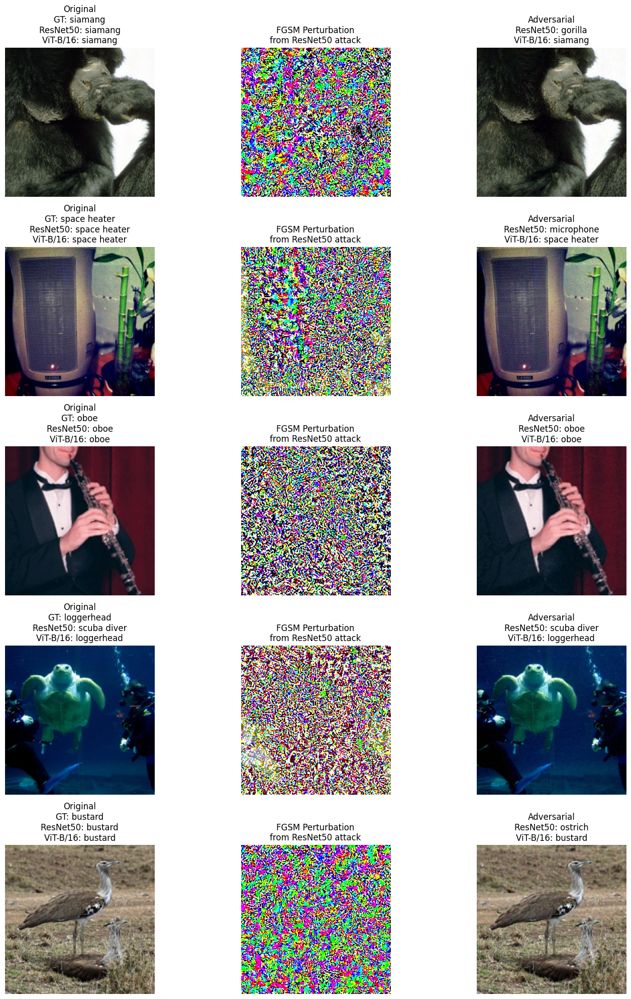

In [22]:
plot_visualization(
    source_model=cnn_model,
    target_model=vit_model,
    clean_images=cnn_inputs,
    adv_images=cnn_fgsm_adv,
    labels=labels,
    indices=sample_indices,
    classes=imagenet_classes,
    attack_name="FGSM Perturbation",
    source_name="ResNet50",
    target_name="ViT-B/16",
)

### 3.2.2. FGSM from ViT-B/16


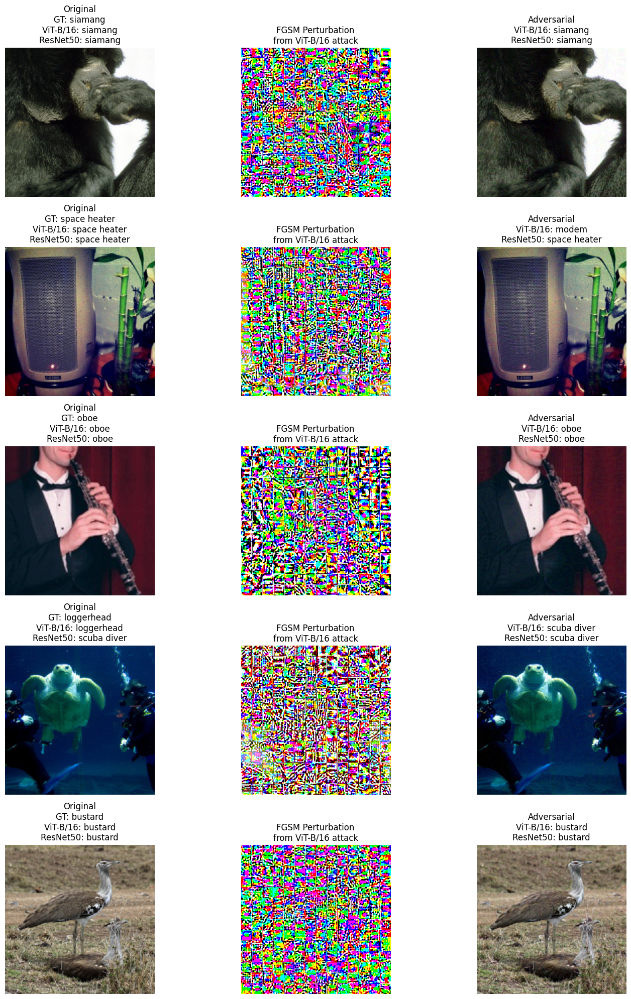

In [23]:
plot_visualization(
    source_model=vit_model,
    target_model=cnn_model,
    clean_images=vit_inputs,
    adv_images=vit_fgsm_adv,
    labels=labels,
    indices=sample_indices,
    classes=imagenet_classes,
    attack_name="FGSM Perturbation",
    source_name="ViT-B/16",
    target_name="ResNet50",
)

### 3.2.3. PGD from ResNet50


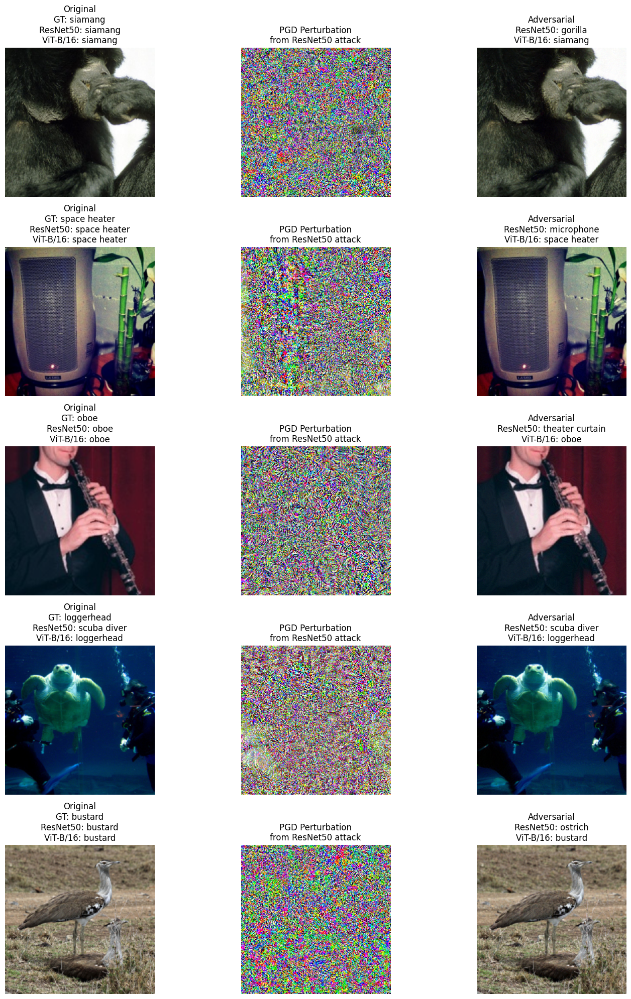

In [24]:
plot_visualization(
    source_model=cnn_model,
    target_model=vit_model,
    clean_images=cnn_inputs,
    adv_images=cnn_pgd_adv,
    labels=labels,
    indices=sample_indices,
    classes=imagenet_classes,
    attack_name="PGD Perturbation",
    source_name="ResNet50",
    target_name="ViT-B/16",
)

### 3.2.4. PGD from ViT-B/16


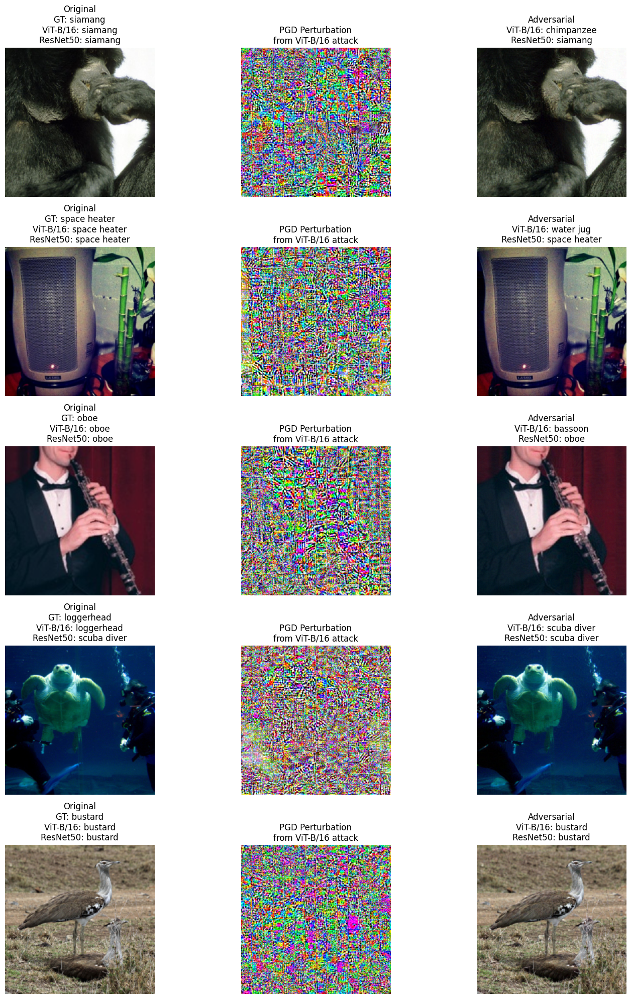

In [25]:
plot_visualization(
    source_model=vit_model,
    target_model=cnn_model,
    clean_images=vit_inputs,
    adv_images=vit_pgd_adv,
    labels=labels,
    indices=sample_indices,
    classes=imagenet_classes,
    attack_name="PGD Perturbation",
    source_name="ViT-B/16",
    target_name="ResNet50",
)